# 📞 Call Duration Analysis: Mean vs. Median

**Business question:** When we report "average handling time" for a customer care team, does the *average* tell the true story?

**What this project covers:**
1. Generating a realistic call-duration dataset
2. Measures of centrality: mean, median, mode
3. Measures of spread: range, IQR, variance, standard deviation
4. Visualizing distributions with histograms (and how bin size changes the story)
5. The effect of a few outliers on the reported KPI

*Data is simulated for learning purposes.*

## 1. Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statistics import multimode

rng = np.random.default_rng(42)   # fixed seed so results are reproducible

## 2. Create the dataset

200 calls. Most calls are short, a few take longer, which is a right-skewed shape typical of real call centers.
Each call also has a categorical field (`call_type`, nominal) and an ordinal field (`priority`).

In [2]:
n = 200
duration = np.round(rng.gamma(shape=4, scale=1.3, size=n), 1)   # minutes
call_type = rng.choice(["Billing", "Technical", "Sales", "General"], size=n, p=[0.35, 0.30, 0.15, 0.20])
priority = rng.choice(["Low", "Medium", "High"], size=n, p=[0.5, 0.35, 0.15])

df = pd.DataFrame({"call_id": range(1001, 1001 + n),
                   "call_type": call_type,
                   "priority": pd.Categorical(priority, categories=["Low", "Medium", "High"], ordered=True),
                   "duration_min": duration})
df.to_csv("calls.csv", index=False)
print(df.head())
print("\nField types:")
print(" call_id      -> nominal (an ID, no math meaning)")
print(" call_type    -> categorical (nominal)")
print(" priority     -> ordinal (Low < Medium < High)")
print(" duration_min -> numerical")

   call_id call_type priority  duration_min
0     1001   General     High           5.6
1     1002   Billing      Low           6.9
2     1003   Billing   Medium           5.1
3     1004   Billing   Medium           4.7
4     1005     Sales      Low           7.3

Field types:
 call_id      -> nominal (an ID, no math meaning)
 call_type    -> categorical (nominal)
 priority     -> ordinal (Low < Medium < High)
 duration_min -> numerical


## 3. Summary statistics

In [3]:
def summarize(x):
    x = np.asarray(x)
    q1, q3 = np.percentile(x, [25, 75])
    return pd.Series({
        "count": len(x),
        "mean": x.mean(),
        "median": np.median(x),
        "mode": multimode(np.round(x).tolist()),   # rounded to whole minutes
        "range": x.max() - x.min(),
        "IQR": q3 - q1,
        "variance (sample)": x.var(ddof=1),
        "std (sample)": x.std(ddof=1),
    })

base = summarize(df["duration_min"])
print(base.to_string(float_format=lambda v: f"{v:.2f}"))

count                       200
mean                       5.34
median                     5.10
mode                 [6.0, 4.0]
range                     15.10
IQR                        3.00
variance (sample)          6.82
std (sample)               2.61


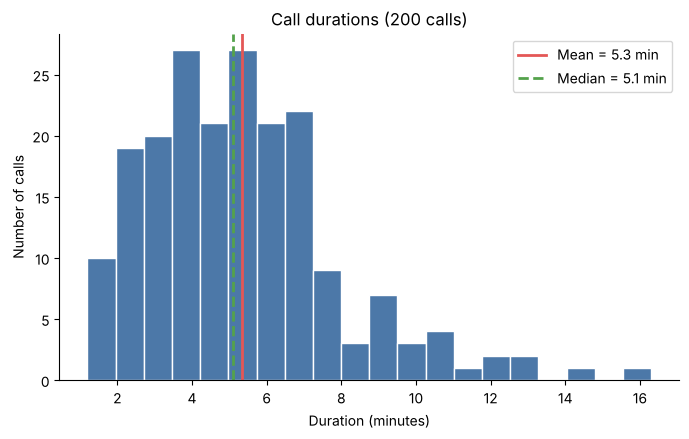

In [4]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(df["duration_min"], bins=20, color="#4C78A8", edgecolor="white")
ax.axvline(base["mean"], color="#E45756", lw=2, label=f"Mean = {base['mean']:.1f} min")
ax.axvline(base["median"], color="#54A24B", lw=2, ls="--", label=f"Median = {base['median']:.1f} min")
ax.set(title="Call durations (200 calls)", xlabel="Duration (minutes)", ylabel="Number of calls")
ax.legend(); ax.spines[["top", "right"]].set_visible(False)
plt.show()

## 4. What happens with a few very long calls?

Add **5 escalated calls** (35–50 minutes), only 2.4% of all calls.

In [5]:
outliers = pd.DataFrame({"call_id": range(2001, 2006),
                         "call_type": "Technical",
                         "priority": pd.Categorical(["High"] * 5, categories=["Low", "Medium", "High"], ordered=True),
                         "duration_min": [35.0, 38.5, 42.0, 46.0, 50.0]})
df_out = pd.concat([df, outliers], ignore_index=True)
with_out = summarize(df_out["duration_min"])

compare = pd.DataFrame({"Normal day": base, "With 5 long calls": with_out}).drop(index=["mode", "count"]).astype(float)
compare["Change %"] = (compare["With 5 long calls"] / compare["Normal day"] - 1) * 100
print(compare.round(2).to_string())

                   Normal day  With 5 long calls  Change %
mean                     5.34               6.24     16.88
median                   5.10               5.10      0.00
range                   15.10              48.80    223.18
IQR                      3.00               3.20      6.67
variance (sample)        6.82              40.01    486.55
std (sample)             2.61               6.33    142.19


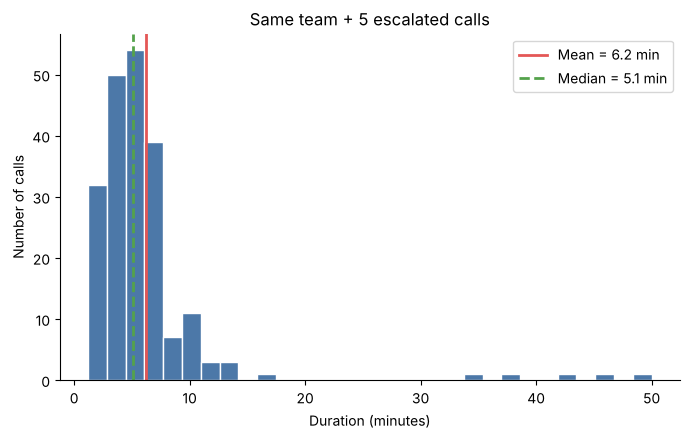

In [6]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(df_out["duration_min"], bins=30, color="#4C78A8", edgecolor="white")
ax.axvline(with_out["mean"], color="#E45756", lw=2, label=f"Mean = {with_out['mean']:.1f} min")
ax.axvline(with_out["median"], color="#54A24B", lw=2, ls="--", label=f"Median = {with_out['median']:.1f} min")
ax.set(title="Same team + 5 escalated calls", xlabel="Duration (minutes)", ylabel="Number of calls")
ax.legend(); ax.spines[["top", "right"]].set_visible(False)
plt.show()

## 5. Does the number of bins change the story?

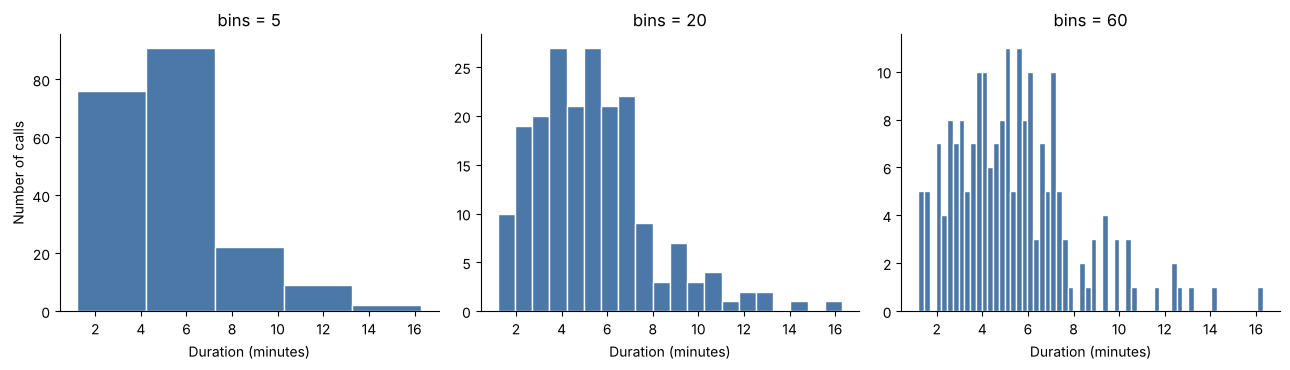

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=False)
for ax, b in zip(axes, [5, 20, 60]):
    ax.hist(df["duration_min"], bins=b, color="#4C78A8", edgecolor="white")
    ax.set(title=f"bins = {b}", xlabel="Duration (minutes)")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Number of calls")
plt.tight_layout(); plt.show()

## 6. Categorical view: calls by type

Mode of call_type: Billing


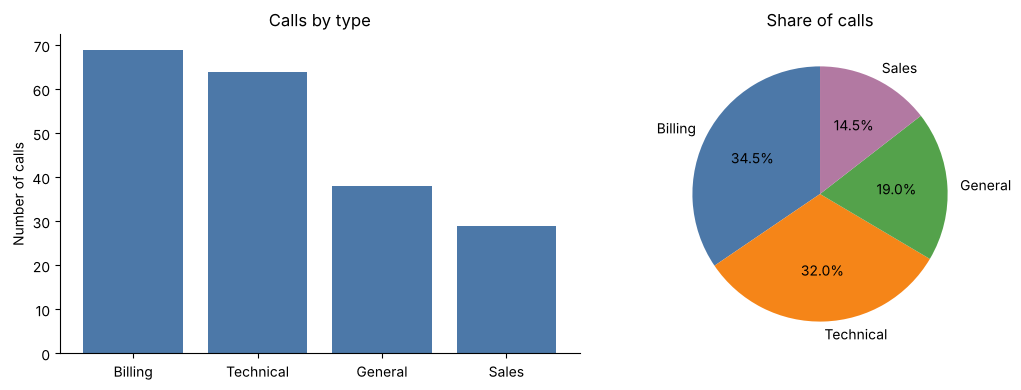

In [8]:
counts = df["call_type"].value_counts()
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.bar(counts.index, counts.values, color="#4C78A8")
ax1.set(title="Calls by type", ylabel="Number of calls"); ax1.spines[["top", "right"]].set_visible(False)
ax2.pie(counts.values, labels=counts.index, autopct="%.1f%%", startangle=90,
        colors=["#4C78A8", "#F58518", "#54A24B", "#B279A2"])
ax2.set(title="Share of calls")
plt.tight_layout(); plt.show()
print("Mode of call_type:", counts.idxmax())

## 7. Key insights

- On a normal day the **mean (5.3 min)** and **median (5.1 min)** are close; the data is only slightly right-skewed.
- Adding just **5 long calls (2.4% of volume)** moved the **mean to 6.2 min (+17%)**, while the **median barely moved (5.1 min)**.
- The **standard deviation jumped from 2.6 to 6.3 min**, but the **IQR stayed almost the same (3.0 → 3.2)**, so IQR is a robust measure of spread.
- **Bin size matters:** 5 bins hide the shape, 60 bins create noise, and ~20 bins show the skew clearly.

**Recommendation:** Report the **median handling time + IQR** as the main KPI, and track long/escalated calls as a **separate metric** so they are investigated rather than hidden inside an average.